# Домашнее задание "Корреляционный и регрессионный анализ"

Инструкции:
- Скачайте файл `practical_module_dataset.csv` и заполните ячейки с заданиями кодом и выводами.
- В каждой задаче требуется: короткая формулировка метода, код и расчёты, численные результаты (коэффициенты, статистики, p-value, CI, R^2) и краткий вывод (1-2 фразы).
- Разрешённые библиотеки: `numpy`, `pandas`, `scipy`, `statsmodels`, `scikit-learn`, `matplotlib`.
- Для воспроизводимости задан `np.random.seed` - не меняйте его.

Формат сдачи: .ipynb с заполненными ячейками, кодом и выводами.

**Выполнил:** Семёшин Владислав Дмитриевич, группа М26-555.

Исходный набор: [practical_module_dataset.csv](https://drive.google.com/file/d/1v05O3zK5m_29SKgY36Nr4_OG0nqZZad4/view). Ноутбук сначала читает CSV рядом с собой, а если файла нет — загружает тот же открытый учебный набор по ссылке. Все проверки значимости выполняются при α = 0,05.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.random.seed(28)
from statsmodels.stats.diagnostic import het_breuschpagan
plt.rcParams.update({'figure.figsize': (8, 5), 'font.size': 10})
alpha = 0.05

In [2]:
try:
    df = pd.read_csv('practical_module_dataset.csv')
except FileNotFoundError:
    df = pd.read_csv('https://drive.google.com/uc?export=download&id=1v05O3zK5m_29SKgY36Nr4_OG0nqZZad4')
print('Размер данных:', df.shape)
print(df.head().to_string(index=False))

Размер данных: (30, 8)
 id  age  height_cm  weight_kg  iq  tv_hours  study_hours  score
  1   24      155.2      51.37  91        11         11.9   76.5
  2   37      184.9      76.49  90        15          4.0   65.4
  3   32      169.8      64.24  98         6         10.6   78.2
  4   28      173.6      68.22  88         9          9.2   75.6
  5   25      174.2      73.80 102         8          8.0   75.1


### Задание 1. Первичный анализ данных (EDA)

- Посмотрите на основные статистические показатели для **всех** переменных.
- Проверьте типы данных и наличие пропусков.
- Постройте гистограммы числовых признаков.
- Запишите наблюдения в текстовой ячейке.

Типы столбцов:
 id               int64
age              int64
height_cm      float64
weight_kg      float64
iq               int64
tv_hours         int64
study_hours    float64
score          float64
Пропуски:
 id             0
age            0
height_cm      0
weight_kg      0
iq             0
tv_hours       0
study_hours    0
score          0
Дубликаты строк: 0
Уникальных id: 30
Описательные статистики всех переменных:
            id     age  height_cm  weight_kg       iq  tv_hours  study_hours   score
count  30.000  30.000     30.000     30.000   30.000    30.000       30.000  30.000
mean   15.500  29.400    169.153     62.734  100.433    12.267        7.640  73.400
std     8.803   6.673      9.584      9.201   12.119     3.832        3.282   8.254
min     1.000  18.000    148.200     44.750   82.000     6.000        2.700  58.900
25%     8.250  24.250    163.250     56.622   91.000     9.000        4.975  67.800
50%    15.500  29.000    169.750     63.675   97.000    12.000        

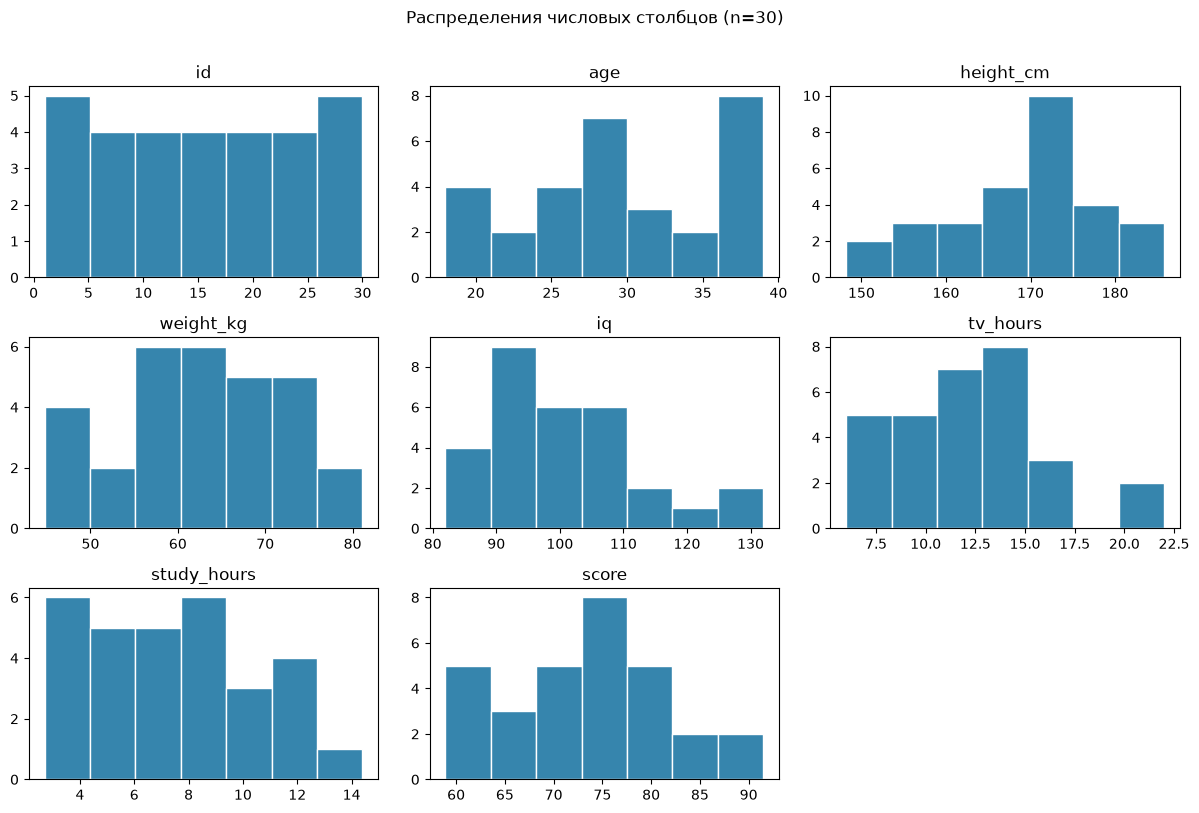

Наблюдения за 1.5 IQR для tv_hours:
 id  tv_hours
 19        22
 29        22


In [3]:
# Метод: описательные статистики, проверка качества, гистограммы.
print('Типы столбцов:\n', df.dtypes.to_string())
print('Пропуски:\n', df.isna().sum().to_string())
print('Дубликаты строк:', df.duplicated().sum())
print('Уникальных id:', df['id'].nunique())
print('Описательные статистики всех переменных:\n', df.describe(include='all').round(3).to_string())
print('Выборочная асимметрия:\n', df.skew().round(3).to_string())
# id показан для полноты, но является идентификатором, а не предиктором.
df.hist(bins=7, figsize=(12, 8), color='#3685ad', edgecolor='white', grid=False)
plt.suptitle('Распределения числовых столбцов (n=30)', y=1.01)
plt.tight_layout()
plt.show()
for col in df.columns.drop('id'):
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3-q1
    unusual = df.loc[(df[col] < q1-1.5*iqr) | (df[col] > q3+1.5*iqr), ['id', col]]
    if len(unusual):
        print(f'Наблюдения за 1.5 IQR для {col}:\n{unusual.to_string(index=False)}')

**Вывод:** в наборе 30 строк и 8 числовых столбцов, пропусков и дубликатов нет; `id` — уникальный идентификатор, поэтому не включается в регрессии. Рост, вес и score приблизительно симметричны, у iq и tv_hours заметна правая асимметрия (около 0,88); два наблюдения с 22 часами просмотра отмечены правилом 1,5 IQR, но без оснований считать их ошибками не удаляются.

### Задание 2. Связь height_cm и weight_kg

- Постройте scatter plot по признакам `height_cm` и `weight_kg`.
- Посчитайте коэффициент Пирсона и p-value.
- Интерпретируйте силу, направление и значимость связи в выводе.

Пирсон: r=0.943533; p-value=5.79897e-15; n=30


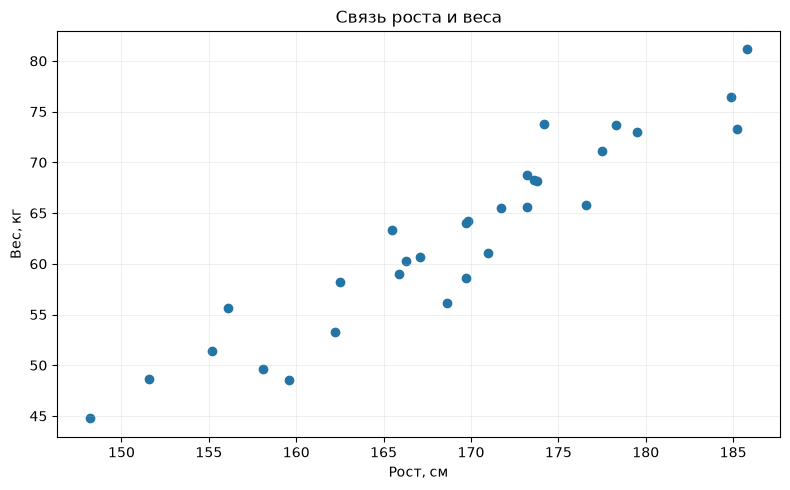

In [4]:
# Метод: коэффициент линейной корреляции Пирсона, двусторонний тест H0: rho=0.
r, p = stats.pearsonr(df['height_cm'], df['weight_kg'])
print(f'Пирсон: r={r:.6f}; p-value={p:.6g}; n={len(df)}')
plt.scatter(df['height_cm'], df['weight_kg'], color='#2474a5')
plt.xlabel('Рост, см'); plt.ylabel('Вес, кг')
plt.title('Связь роста и веса'); plt.grid(alpha=0.2)
plt.tight_layout(); plt.show()

**Вывод:** линейная связь роста и веса сильная и положительная: r = 0,9435, p ≈ 5,80·10⁻¹⁵ < 0,05. В этой выборке более высокий рост связан с большим весом; корреляция сама по себе не устанавливает причинность.

### Задание 3. Связь tv_hours и iq

- Посчитайте ранговый коэффициент Спирмена между `tv_hours` и `iq` и p-value.
- Оцените, есть ли монотонная связь в выводе.

In [5]:
# Метод: ранговая корреляция Спирмена, двусторонняя H1: rho_s != 0.
rs, ps = stats.spearmanr(df['tv_hours'], df['iq'])
print(f'Спирмен: r_s={rs:.6f}; p-value={ps:.6f}')

Спирмен: r_s=-0.210782; p-value=0.263541


**Вывод:** оценка связи tv_hours и iq слабо отрицательна (rₛ = −0,2108), но незначима (p = 0,2635). Данных недостаточно для вывода о монотонной связи в генеральной совокупности; это не является доказательством её отсутствия.

### Задание 4. Простая линейная регрессия weight_kg ~ height_cm

- Постройте регрессию, найдите intercept и slope, 95% доверительный интервал для наклона.
- Интерпретируйте результат в выводе.

In [6]:
# Метод: OLS со свободным членом и t-интервал для наклона.
X_simple = sm.add_constant(df[['height_cm']])
simple = sm.OLS(df['weight_kg'], X_simple).fit()
ci_slope = simple.conf_int(alpha=alpha).loc['height_cm']
print(f'intercept={simple.params["const"]:.6f}; slope={simple.params["height_cm"]:.6f}')
print(f'95% ДИ наклона: [{ci_slope.iloc[0]:.6f}; {ci_slope.iloc[1]:.6f}] кг/см')
print(f'R²={simple.rsquared:.6f}; p наклона={simple.pvalues["height_cm"]:.6g}')

intercept=-90.496227; slope=0.905866
95% ДИ наклона: [0.782744; 1.028988] кг/см
R²=0.890255; p наклона=5.79897e-15


**Вывод:** модель имеет вид weight_kg = −90,4962 + 0,9059·height_cm: увеличение роста на 1 см связано в среднем с увеличением веса на 0,906 кг. 95%-й интервал наклона [0,7827; 1,0290] кг/см исключает ноль; свободный член не следует трактовать как реальный вес при нулевом росте — это далеко за диапазоном данных.

### Задание 5. Прогноз и предсказательный интервал

- Для `height_cm = 175` вычислите точечный прогноз веса и 95% предсказательный интервал для нового наблюдения.

In [7]:
# Метод: предсказательный интервал OLS для нового наблюдения,
# включающий как неопределённость среднего, так и индивидуальный разброс.
new_x = pd.DataFrame({'const': [1.0], 'height_cm': [175.0]})
prediction = simple.get_prediction(new_x).summary_frame(alpha=alpha)
print(prediction[['mean', 'obs_ci_lower', 'obs_ci_upper']].round(6).to_string(index=False))

     mean  obs_ci_lower  obs_ci_upper
68.030296     61.530687     74.529904


**Вывод:** при росте 175 см прогноз веса равен 68,03 кг; 95%-й предсказательный интервал для нового человека составляет [61,53; 74,53] кг при предпосылках модели. Это интервал для индивидуального наблюдения, а не доверительный интервал для среднего веса.

### Задание 6. Множественная регрессия

- Постройте модель score `~ study_hours + iq + tv_hours + age`.
- Выведите R^2 и оцените значимость предикторов по p-value.
- Дополнительно проверьте мультиколлинеарность через VIF.
- Запшите наблюдения в выводе.

In [8]:
# Метод: множественная OLS-регрессия с константой.
predictors = ['study_hours', 'iq', 'tv_hours', 'age']
X_multi = sm.add_constant(df[predictors])
multi = sm.OLS(df['score'], X_multi).fit()
coef_table = pd.DataFrame({'coef': multi.params, 'std_error': multi.bse,
                           't': multi.tvalues, 'p_value': multi.pvalues})
print(coef_table.to_string(float_format=lambda v: f'{v:.8g}'))
print(f'R²={multi.rsquared:.6f}; скорректированный R²={multi.rsquared_adj:.6f}')
vif = pd.DataFrame({'feature': predictors,
                   'VIF': [variance_inflation_factor(X_multi.to_numpy(), i)
                           for i in range(1, X_multi.shape[1])]})
print('VIF предикторов (константа учтена в вспомогательных регрессиях):')
print(vif.round(6).to_string(index=False))

                    coef   std_error           t       p_value
const          45.658396   6.8069934   6.7075716 4.9798843e-07
study_hours    2.0978343  0.19339233   10.847557 6.0564094e-11
iq            0.14793044 0.053118493   2.7849142   0.010059232
tv_hours     -0.14469817  0.15855808 -0.91258776    0.37017643
age         -0.046531746  0.09113023 -0.51060714     0.6141056
R²=0.874073; скорректированный R²=0.853925
VIF предикторов (константа учтена в вспомогательных регрессиях):
    feature      VIF
study_hours 1.173723
         iq 1.207710
   tv_hours 1.075912
        age 1.077568


**Вывод:** модель объясняет 87,4% выборочной вариации score (скорректированный R² ≈ 0,854); при учёте остальных признаков значимы положительные коэффициенты study_hours (≈2,098) и iq (≈0,148), а tv_hours (p ≈ 0,370) и age (p ≈ 0,614) незначимы. VIF всех предикторов составляет 1,08–1,21, поэтому признаков выраженной мультиколлинеарности нет.

### Задание 7. Ошибка модели

- Оцените типичную ошибку предсказаний модели из задания 6: вычислите RMSE (корень из средней квадратичной ошибки) на всей выборке и сравните её с разбросом целевой переменной (стандартным отклонением score).
- Насколько модель уменьшает типичную ошибку?

In [9]:
# Метод: RMSE на всей выборке, как требует задание.
rmse = np.sqrt(np.mean((df['score'] - multi.fittedvalues)**2))
score_sd = df['score'].std(ddof=1)
# Для строго сопоставимого baseline берём RMSE прогноза средним (ddof=0).
baseline_rmse = np.sqrt(np.mean((df['score'] - df['score'].mean())**2))
print(f'RMSE модели={rmse:.6f}; выборочное SD(score)={score_sd:.6f}')
print(f'RMSE константного прогноза средним={baseline_rmse:.6f}')
print(f'Снижение ошибки относительно SD: {100*(1-rmse/score_sd):.2f}%')
print(f'Снижение RMSE относительно константного прогноза: {100*(1-rmse/baseline_rmse):.2f}%')

RMSE модели=2.879693; выборочное SD(score)=8.253693
RMSE константного прогноза средним=8.114966
Снижение ошибки относительно SD: 65.11%
Снижение RMSE относительно константного прогноза: 64.51%


**Вывод:** RMSE = 2,880 балла против выборочного стандартного отклонения score = 8,254 (меньше примерно на 65,1%); относительно сопоставимого прогноза средним RMSE снижается на 64,5%. Это оценка на обучающей выборке, поэтому она не характеризует без смещения качество на новых данных.

### Задание 8. Градиентный спуск

- Реализуйте градиентный спуск для простой регрессии score `~ study_hours` и сравните коэффициенты со `statsmodels`.
- Ответьте на вопрос: возможно ли получить метрику алгоритмом градиентного спуска лучше, чем у МНК?

learning_rate=0.05; iterations=2000; начальные коэффициенты=[0,0]
GD:  intercept=56.0340284093; slope=2.2730329307
OLS: intercept=56.0340284093; slope=2.2730329307
RMSE GD=3.4740349937
RMSE OLS=3.4740349937
Максимальное отличие коэффициентов: 4.973799150320701e-14


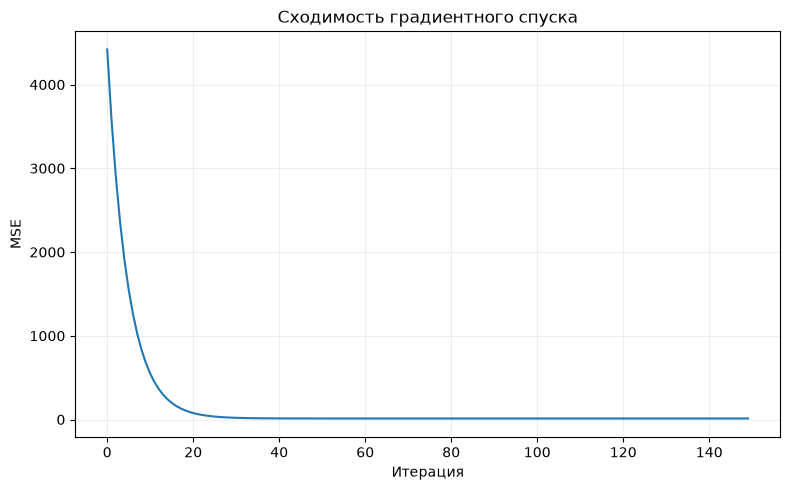

In [10]:
# Метод: полный градиентный спуск по MSE для прямой с константой.
# Стандартизация x улучшает обусловленность; ниже возвращаем исходный масштаб.
x = df['study_hours'].to_numpy()
y = df['score'].to_numpy()
x_mean, x_scale = x.mean(), x.std(ddof=0)
X_gd = np.column_stack([np.ones(len(x)), (x-x_mean)/x_scale])
theta = np.zeros(2)
learning_rate, n_iterations = 0.05, 2000
losses = []
for _ in range(n_iterations):
    error = X_gd @ theta - y
    gradient = 2/len(y) * X_gd.T @ error
    theta -= learning_rate * gradient
    losses.append(np.mean((X_gd @ theta-y)**2))
slope_gd = theta[1]/x_scale
intercept_gd = theta[0] - slope_gd*x_mean
ols_gd = sm.OLS(y, sm.add_constant(x)).fit()
pred_gd = intercept_gd + slope_gd*x
print(f'learning_rate={learning_rate}; iterations={n_iterations}; начальные коэффициенты=[0,0]')
print(f'GD:  intercept={intercept_gd:.10f}; slope={slope_gd:.10f}')
print(f'OLS: intercept={ols_gd.params[0]:.10f}; slope={ols_gd.params[1]:.10f}')
print(f'RMSE GD={np.sqrt(np.mean((pred_gd-y)**2)):.10f}')
print(f'RMSE OLS={np.sqrt(np.mean(ols_gd.resid**2)):.10f}')
print('Максимальное отличие коэффициентов:', np.max(np.abs([intercept_gd, slope_gd]-ols_gd.params)))
assert np.allclose([intercept_gd, slope_gd], ols_gd.params, atol=1e-8)
plt.plot(losses[:150]); plt.xlabel('Итерация'); plt.ylabel('MSE')
plt.title('Сходимость градиентного спуска'); plt.grid(alpha=0.2)
plt.tight_layout(); plt.show()

**Вывод:** градиентный спуск с шагом 0,05 за 2000 итераций сходится к коэффициентам OLS с точностью вычислений. Для той же линейной модели и той же обучающей выборки получить меньшую MSE/RMSE, чем у точного МНК, невозможно: МНК уже минимизирует сумму квадратов; на новых данных качество может различаться, например, при регуляризации или ранней остановке, но это другая постановка.

### Задание 9. Бутстрэп-интервал для корреляции

- Постройте бутстрэп-оценку 95% доверительного интервала для коэффициента Пирсона между `height_cm` и `weight_kg` (1000 бутстрэп-итераций, перцентильный метод).

In [11]:
# Метод: парный бутстрэп строк (сохраняем пары рост–вес),
# 1000 повторов и перцентили 2.5%/97.5%. Seed из шаблона сохранён.
np.random.seed(28)
n_bootstrap = 1000
bootstrap_r = np.empty(n_bootstrap)
height = df['height_cm'].to_numpy()
weight = df['weight_kg'].to_numpy()
for b in range(n_bootstrap):
    indices = np.random.choice(len(df), size=len(df), replace=True)
    bootstrap_r[b] = stats.pearsonr(height[indices], weight[indices]).statistic
ci_r = np.quantile(bootstrap_r, [0.025, 0.975])
print(f'Повторов={n_bootstrap}; seed=28')
print(f'95% перцентильный ДИ Пирсона: [{ci_r[0]:.6f}; {ci_r[1]:.6f}]')

Повторов=1000; seed=28
95% перцентильный ДИ Пирсона: [0.902085; 0.970499]


**Вывод:** 95%-й бутстрэп-интервал корреляции [0,9021; 0,9705] целиком положителен и соответствует сильной линейной связи. Ресемплинг выполнен по целым парам наблюдений, поэтому исходная связь между ростом и весом сохранена.

### Задание 10. Диагностика остатков

Для модели из задания 6 проведите диагностику остатков:
- постройте график остатков против предсказанных значений,
- QQ-plot остатков и гистограмму остатков.

Сделайте вывод о выполнении предпосылок регрессии.

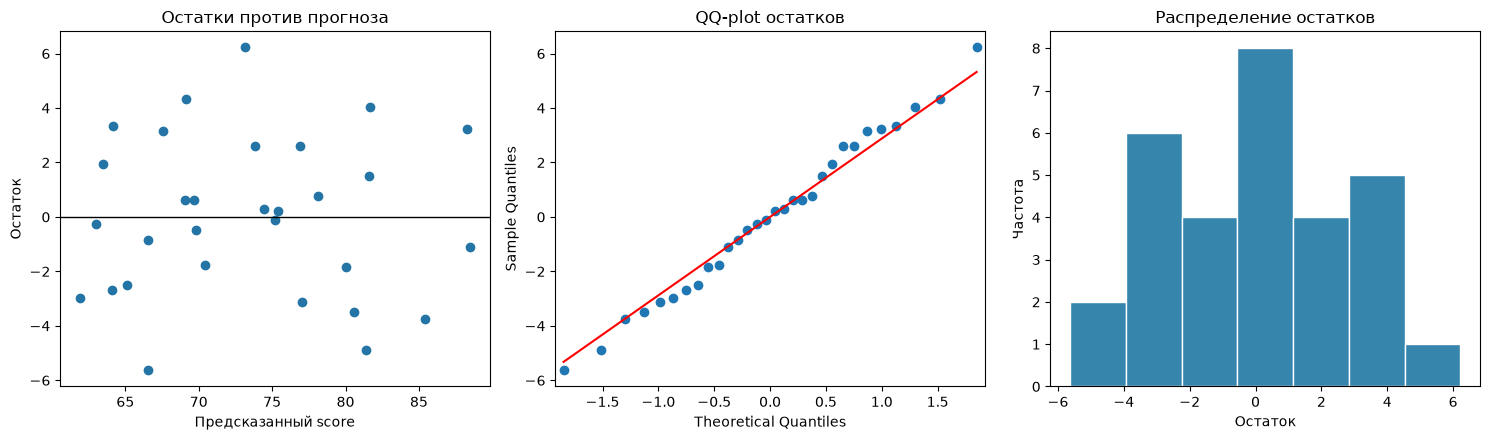

Средний остаток=5.21e-14
Шапиро–Уилк: p=0.961592
Бройш–Паган: LM=0.318891; p=0.988562


In [12]:
# Метод: графическая диагностика линейности, формы и разброса ошибок.
residuals, fitted = multi.resid, multi.fittedvalues
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].scatter(fitted, residuals, color='#2474a5')
axes[0].axhline(0, color='black', lw=1)
axes[0].set(xlabel='Предсказанный score', ylabel='Остаток', title='Остатки против прогноза')
sm.qqplot(residuals, line='s', ax=axes[1])
axes[1].set_title('QQ-plot остатков')
axes[2].hist(residuals, bins=7, color='#3685ad', edgecolor='white')
axes[2].set(xlabel='Остаток', ylabel='Частота', title='Распределение остатков')
plt.tight_layout(); plt.show()
print(f'Средний остаток={residuals.mean():.3g}')
print(f'Шапиро–Уилк: p={stats.shapiro(residuals).pvalue:.6f}')
lm, bp_p, f_stat, f_p = het_breuschpagan(residuals, multi.model.exog)
print(f'Бройш–Паган: LM={lm:.6f}; p={bp_p:.6f}')

**Вывод:** остатки центрированы около нуля, на графике против прогнозов нет выраженной кривизны или веерообразного изменения разброса, QQ-plot близок к прямой; проверки Шапиро (p ≈ 0,962) и Бройша–Пагана (p ≈ 0,989) не выявляют отклонений от нормальности и постоянной дисперсии. При n = 30 это не доказывает выполнение предпосылок; независимость наблюдений определяется схемой сбора данных и не может быть установлена по этим графикам.